Week 4 Jupyter Notebook

My project looks at why some people struggle with their mental health more than others, focusing on everyday factors like money, jobs, physical health and access to medical care. The goal is to see whether these factors can flag who is most at risk, which could help health agencies decide where to focus support.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score, ConfusionMatrixDisplay

I'm using the CDC's Behavioral Risk Factor Surveillance System (BRFSS), a yearly phone survey of hundreds of thousands of American adults about their health and daily lives. This week I used the CDC's own definition of "frequent mental distress" (14 or more bad mental health days in a month), which applies to about 14% of people in my 50,000-person sample.

In [2]:
full_df = pd.read_sas('LLCP2024.XPT ', format='xport')
cols = ['MENTHLTH','PHYSHLTH','INCOME3','EMPLOY1','_HLTHPL2',
        'MEDCOST1','GENHLTH','_AGE_G','_BMI5']
brfss = full_df[cols].copy(); del full_df

for c in ['MENTHLTH','PHYSHLTH']:
    brfss[c] = brfss[c].replace({88: 0, 77: np.nan, 99: np.nan})
brfss['INCOME3']  = brfss['INCOME3'].replace({77: np.nan, 99: np.nan})
brfss['EMPLOY1']  = brfss['EMPLOY1'].replace({9: np.nan})
brfss['_HLTHPL2'] = brfss['_HLTHPL2'].replace({9: np.nan})
brfss['MEDCOST1'] = brfss['MEDCOST1'].replace({7: np.nan, 9: np.nan})
brfss['GENHLTH']  = brfss['GENHLTH'].replace({7: np.nan, 9: np.nan})
brfss['_BMI5']    = brfss['_BMI5'] / 100

brfss = brfss.dropna()
brfss = pd.get_dummies(brfss, columns=['EMPLOY1'], drop_first=True, dtype=int)
brfss = brfss.sample(50_000, random_state=42)
print(brfss.shape)

(50000, 15)


In [3]:
brfss['FMD'] = (brfss['MENTHLTH'] >= 14).astype(int)
print(brfss['FMD'].value_counts(normalize=True).round(3))

X = brfss.drop(columns=['MENTHLTH', 'FMD']); y = brfss['FMD']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          stratify=y, random_state=42)

FMD
0    0.859
1    0.141
Name: proportion, dtype: float64


In [4]:
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

results = []
for label, (Xa, Xb) in {'Unscaled': (X_tr, X_te), 'Scaled': (X_tr_s, X_te_s)}.items():
    m = LogisticRegression(max_iter=100, class_weight='balanced')
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        m.fit(Xa, y_tr)
    prob = m.predict_proba(Xb)[:, 1]; pred = m.predict(Xb)
    results.append({'model': label,
                    'iterations': m.n_iter_[0],
                    'converged': not any('converge' in str(x.message) for x in w),
                    'accuracy': accuracy_score(y_te, pred),
                    'recall':   recall_score(y_te, pred),
                    'AUC':      roc_auc_score(y_te, prob)})
    if label == 'Scaled': scaled_model, scaled_pred = m, pred

print(pd.DataFrame(results).round(3))

      model  iterations  converged  accuracy  recall    AUC
0  Unscaled         100      False     0.739   0.660  0.776
1    Scaled          10       True     0.738   0.657  0.777


I used logistic regression to predict whether each person is in frequent mental distress, and ran it twice: once on the raw data and once after feature scaling, which puts every factor on the same scale. Because only 14% of people are in distress, I weighted the model so it couldn't score well just by guessing "no" for everyone.

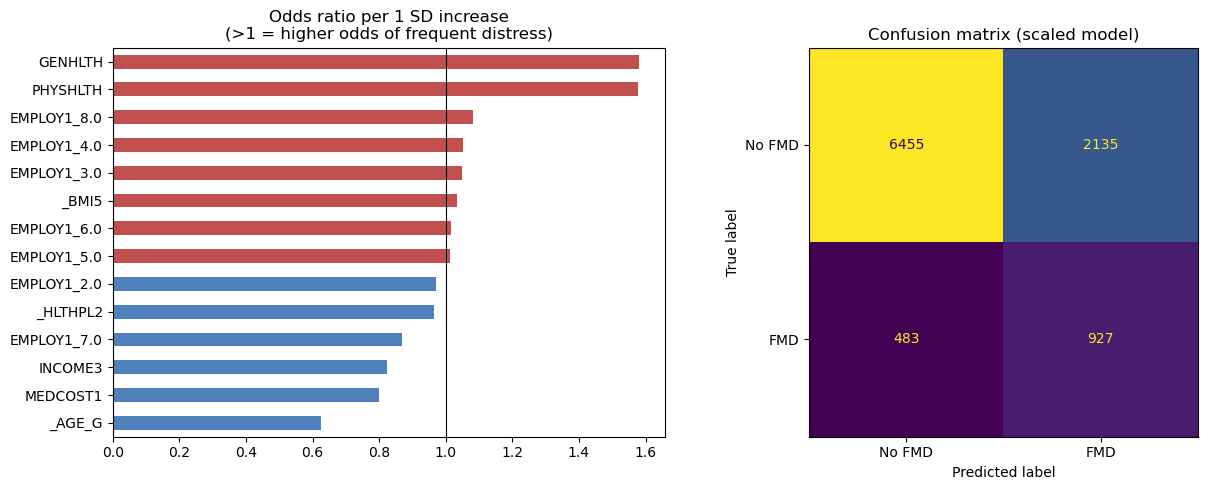

In [5]:
odds = pd.Series(np.exp(scaled_model.coef_[0]), index=X.columns).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
odds.plot.barh(ax=ax[0], color=['#c0504d' if v > 1 else '#4f81bd' for v in odds])
ax[0].axvline(1, color='k', lw=.8)
ax[0].set_title('Odds ratio per 1 SD increase\n(>1 = higher odds of frequent distress)')
ConfusionMatrixDisplay.from_predictions(y_te, scaled_pred, ax=ax[1],
                                        display_labels=['No FMD', 'FMD'], colorbar=False)
ax[1].set_title('Confusion matrix (scaled model)')
plt.tight_layout(); plt.show()

Scaling didn't change accuracy (74%) or AUC (0.78), but the scaled model finished in 10 steps while the unscaled one never settled on an answer, and only scaled results can be fairly compared. Poor physical and general health raised the odds of distress the most, by about 58% each. Older age, higher income and not facing cost barriers to care all lowered it, and the model caught about two-thirds of people in distress (recall = 0.66).